# Exercício 1: ler os dados

In [4]:
import pandas as pd

df = pd.read_csv("tempo_reacao.csv")
print(df.shape)
print(df.head())
print(df.isna().sum())
print(df.duplicated().sum())

(25, 4)
  participante       mao  tentativa  tempo_ms
0          Ana   direita          1     312.0
1          Ana   direita          2     287.0
2          Ana   direita          3     265.0
3          Ana  esquerda          1     341.0
4          Ana  esquerda          2     318.0
participante    0
mao             0
tentativa       0
tempo_ms        2
dtype: int64
1


# Exercício 2: limpar os dados

In [5]:
df = df.drop_duplicates()
df = df.dropna(subset=["tempo_ms"])
df["tempo_ms"] = df["tempo_ms"].astype(int)
print(df.shape)
print(df.dtypes)


(22, 4)
participante      str
mao               str
tentativa       int64
tempo_ms        int64
dtype: object


# Exercício 3: agrupar e calcular médias

In [6]:
media_mao = df.groupby("mao")["tempo_ms"].mean().round(1)
print(media_mao)

media_tentativa = df.groupby("tentativa")["tempo_ms"].mean().round(1)
print(media_tentativa)

mao
direita     280.3
esquerda    317.7
Name: tempo_ms, dtype: float64
tentativa
1    320.2
2    294.9
3    273.6
Name: tempo_ms, dtype: float64


# Exercício 4: gráfico de linhas

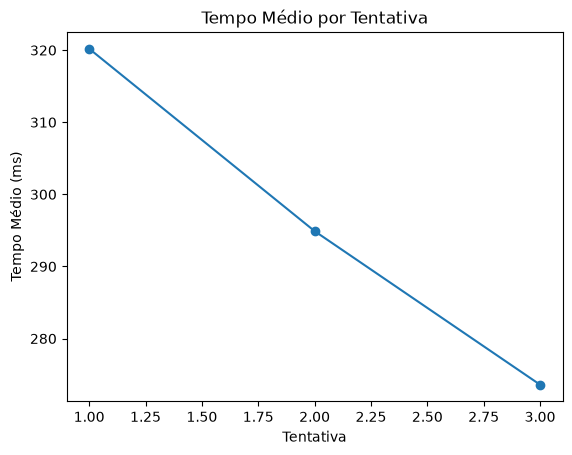

In [12]:
import matplotlib.pyplot as plt
media_tentativa.plot(kind="line", marker="o")
plt.title("Tempo Médio por Tentativa")
plt.xlabel("Tentativa")
plt.ylabel("Tempo Médio (ms)")
plt.show()

# Exercício 5: gráfico de barras e imagem guardada

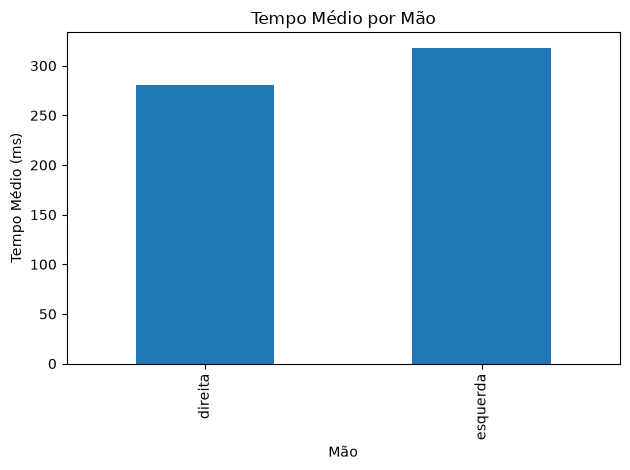

In [15]:
import matplotlib.pyplot as plt
media_mao.plot(kind="bar")
plt.title("Tempo Médio por Mão")
plt.xlabel("Mão")
plt.ylabel("Tempo Médio (ms)")
plt.tight_layout()
plt.savefig("tempo_mao.png")
plt.show()


# Extensão 1 (opcional): o participante mais rápido

participante
Ana       303.2
Bruno     291.0
Carla     306.4
Duarte    289.2
Name: tempo_ms, dtype: float64
Duarte
289.2


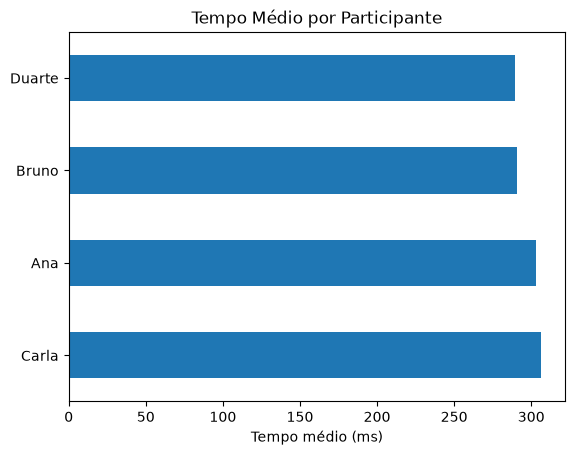

In [21]:
media_participante = df.groupby("participante")["tempo_ms"].mean().round(1)
print(media_participante)
print(media_participante.idxmin())
print(media_participante.min())
media_participante.sort_values(ascending=False).plot(kind="barh")
plt.title("Tempo Médio por Participante")
plt.xlabel("Tempo médio (ms)")
plt.ylabel("")
plt.show()

# Extensão 2 (opcional): os resultados de uma sondagem

resposta
A pé         15
Autocarro    34
Bicicleta     3
Carro        28
Name: votos, dtype: int64


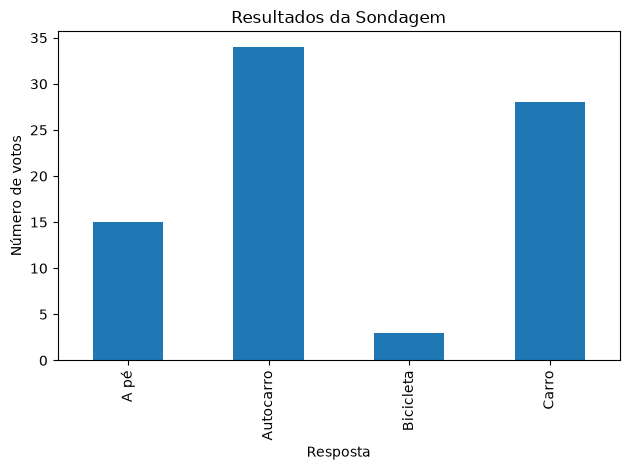

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

sond = pd.read_csv("sondagem.csv")
resultados = sond.groupby("resposta")["votos"].sum()
print(resultados)

resultados.plot(kind="bar")
plt.title("Resultados da Sondagem")
plt.xlabel("Resposta")
plt.ylabel("Número de votos")
plt.tight_layout()
plt.savefig("sondagem.png")
plt.show()